# 09a · Qualidade: Pareto das perdas, Ishikawa da cadeia do frio e FMEA do recebimento refrigerado
A Fase 8 mostrou que **perdas de produto são ~63% do custo do CD**. Aqui aplicamos as ferramentas da
qualidade para atacar a causa:
1. **Pareto:** quais perdas e defeitos concentram o valor?
2. **Ishikawa (6M):** quais causas explicam a perda por frio, com evidência dos dados?
3. **FMEA** do recebimento refrigerado: modos de falha priorizados por risco (RPN), antes e depois
   das ações.

Valores do ano-base (nov/2025–out/2026), **escala cheia**, a custo do produto.

*EN summary: Pareto of losses and quality defects, 6M fishbone for cold-chain losses with data
evidence, and an FMEA of refrigerated receiving with RPN before/after actions.*

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dcanalysis import q, save, savefig, log, params, ROOT

NB = "09a"
PH9 = ROOT / "reports" / "phase9"
P = params(); C = P["costs"]
INI, FIM = C["base_year"]
K = P["simulation"]["scale_factor"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160)

## 1. Pareto das perdas e defeitos de qualidade
Cada item é uma **causa operacional**, não só um tipo contábil. Por exemplo, a perda por frio é separada
em evento (falha de jan/2026) e crônica, e o vencimento em lotes que **chegaram** abaixo de 70% de vida
útil e demais.

In [2]:
baixas = q("""SELECT m.date_key, s.zone, REPLACE(m.movement_type, 'WRITE_OFF_', '') AS tipo, m.lot_id,
                     m.qty_units * s.unit_cost AS custo
              FROM fact_movement m JOIN dim_sku s ON s.sku_id = m.sku_id
              WHERE m.movement_type LIKE 'WRITE_OFF_%' AND m.date_key >= :i AND m.date_key < :f""", i=INI, f=FIM)
vida = q("""SELECT lot_id, AVG(remaining_life_pct) AS vida FROM fact_receipt
            WHERE status = 'ACCEPTED' GROUP BY lot_id""")
baixas = baixas.merge(vida, on="lot_id", how="left")
evento = baixas.date_key.between("2026-01-06", "2026-01-18")
zona_pt = {"chilled": "resfriado", "frozen": "congelado", "dry": "seco"}
def causa(r, ev):
    if r.tipo == "COLD_CHAIN":
        return "Frio: falha de jan/2026 (evento)" if ev else f"Frio crônico: {zona_pt[r.zone]}"
    if r.tipo == "EXPIRY":
        return "Vencimento: lote aceito < 70% de vida" if r.vida < 70 else "Vencimento: demais lotes"
    return {"RECALL": "Recall (lote de fornecedor)", "DAMAGE": "Avaria no armazém"}[r.tipo]
baixas["causa"] = [causa(r, e) for r, e in zip(baixas.itertuples(), evento)]

dev = q("""SELECT r.reason, r.disposition, r.qty_units * s.unit_cost AS custo FROM fact_return r
           JOIN dim_sku s ON s.sku_id = r.sku_id WHERE r.return_date >= :i AND r.return_date < :f""", i=INI, f=FIM)
dev = dev[dev.disposition == "SCRAP"]                      # devolução que vira descarte = perda de produto
nome_dev = {"DAMAGED": "Devolução: avaria no transporte/manuseio", "EXPIRING_SOON": "Devolução: validade curta",
            "REFUSED": "Devolução: recusa do cliente", "WRONG_ITEM": "Devolução: item errado (erro de separação)"}
dev["causa"] = dev.reason.map(nome_dev)

pareto = (pd.concat([baixas[["causa", "custo"]], dev[["causa", "custo"]]])
          .groupby("causa").custo.sum().mul(K).sort_values(ascending=False).to_frame("R$_ano"))
pareto["pct"] = 100 * pareto["R$_ano"] / pareto["R$_ano"].sum()
pareto["pct_acum"] = pareto.pct.cumsum()
save(pareto.reset_index().round(1), "09a_pareto_perdas", out=PH9)
(pareto.assign(**{"R$_ano": pareto["R$_ano"] / 1e6}).rename(columns={"R$_ano": "R$ mi/ano"})).round(2)

,R$ mi/ano,pct,pct_acum
causa,,,
Frio crônico: congelado,24.76,35.31,35.31
Frio: falha de jan/2026 (evento),20.68,29.49,64.80
Frio crônico: resfriado,10.58,15.08,79.88
Devolução: avaria no transporte/manuseio,4.55,6.49,86.37
Devolução: validade curta,2.88,4.11,90.48
Recall (lote de fornecedor),1.85,2.63,93.12
Vencimento: lote aceito < 70% de vida,1.31,1.87,94.99
Devolução: recusa do cliente,1.19,1.70,96.69
Avaria no armazém,1.03,1.46,98.15


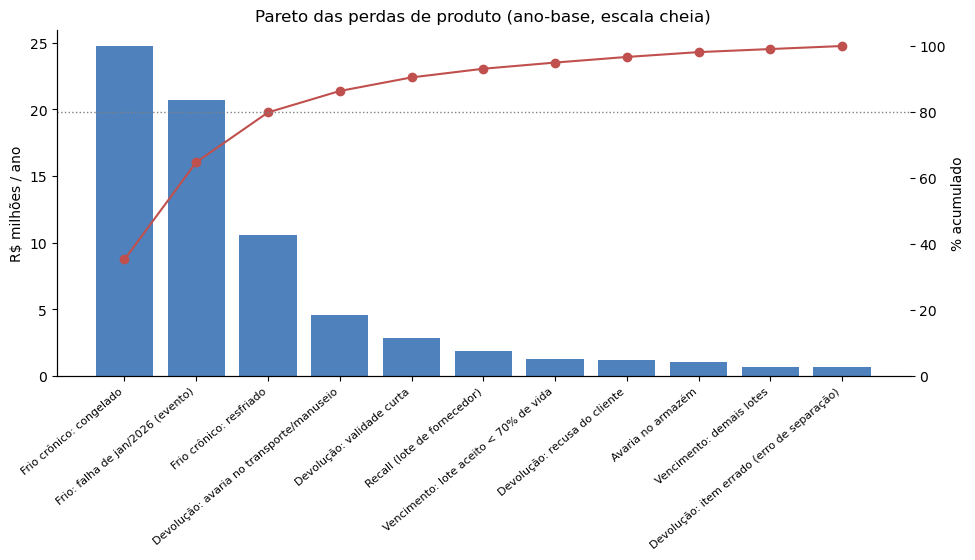

In [3]:
# Pareto clássico: barras (valor) + linha do acumulado; ordena causas e mostra onde está 80% do problema.
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(range(len(pareto)), pareto["R$_ano"] / 1e6, color="#4F81BD")
ax.set_xticks(range(len(pareto)), pareto.index, rotation=40, ha="right", fontsize=8)
ax.set_ylabel("R$ milhões / ano")
ax2 = ax.twinx(); ax2.plot(range(len(pareto)), pareto.pct_acum, color="#C0504D", marker="o")
ax2.axhline(80, color="grey", ls=":", lw=1); ax2.set_ylim(0, 105); ax2.set_ylabel("% acumulado")
ax.set_title("Pareto das perdas de produto (ano-base, escala cheia)")
savefig(fig, "09a_pareto", out=PH9)

**Leitura:** **duas a três causas concentram ~80%** do valor, todas da **cadeia do frio** (crônica no
congelado e no resfriado e o evento de jan/2026). As causas de armazém "clássicas" (avaria, erro de
separação) são pequenas em R$. O foco do programa de qualidade está definido: **recebimento e
armazenagem refrigerados**.

## 2. Ishikawa (6M) da perda por frio, com evidência dos dados

In [4]:
ev = {}
r = q("""SELECT zone, status, truck_temp_c, dock_exposure_min, remaining_life_pct FROM fact_receipt
         WHERE zone <> 'dry' AND arrival_ts >= :i AND arrival_ts < :f""", i=INI, f=FIM)
ac = r[r.status == "ACCEPTED"]
lim = ac.zone.map(P["operations"]["max_dock_exposure_min"])
ev["exp_res"] = 100 * (ac[ac.zone == "chilled"].dock_exposure_min > 30).mean()
ev["exp_cong"] = 100 * (ac[ac.zone == "frozen"].dock_exposure_min > 15).mean()
ev["temp_cong"] = 100 * (ac[ac.zone == "frozen"].truck_temp_c > -18).mean()
chegada = q("""SELECT CAST(substr(arrival_ts, 12, 2) AS INTEGER) AS h FROM fact_receipt
               WHERE zone <> 'dry' AND arrival_ts >= :i AND arrival_ts < :f""", i=INI, f=FIM)
ev["pico_manha"] = 100 * chegada.h.between(7, 11).mean()
put = q("""SELECT putaway_shift, COUNT(*) AS n FROM fact_receipt WHERE zone <> 'dry' AND status = 'ACCEPTED'
           AND arrival_ts >= :i AND arrival_ts < :f GROUP BY 1""", i=INI, f=FIM)
ev["occ_pico"] = q("""SELECT MAX(100.0 * (rack_pallets + overflow_pallets) / rack_positions_total) AS m
                      FROM fact_occupancy_daily WHERE zone = 'frozen'""").m[0]
for k, v in ev.items():
    print(f"{k:10s} {v:5.1f}")

exp_res     27.1
exp_cong    62.7
temp_cong   17.3
pico_manha  72.6
occ_pico   110.4


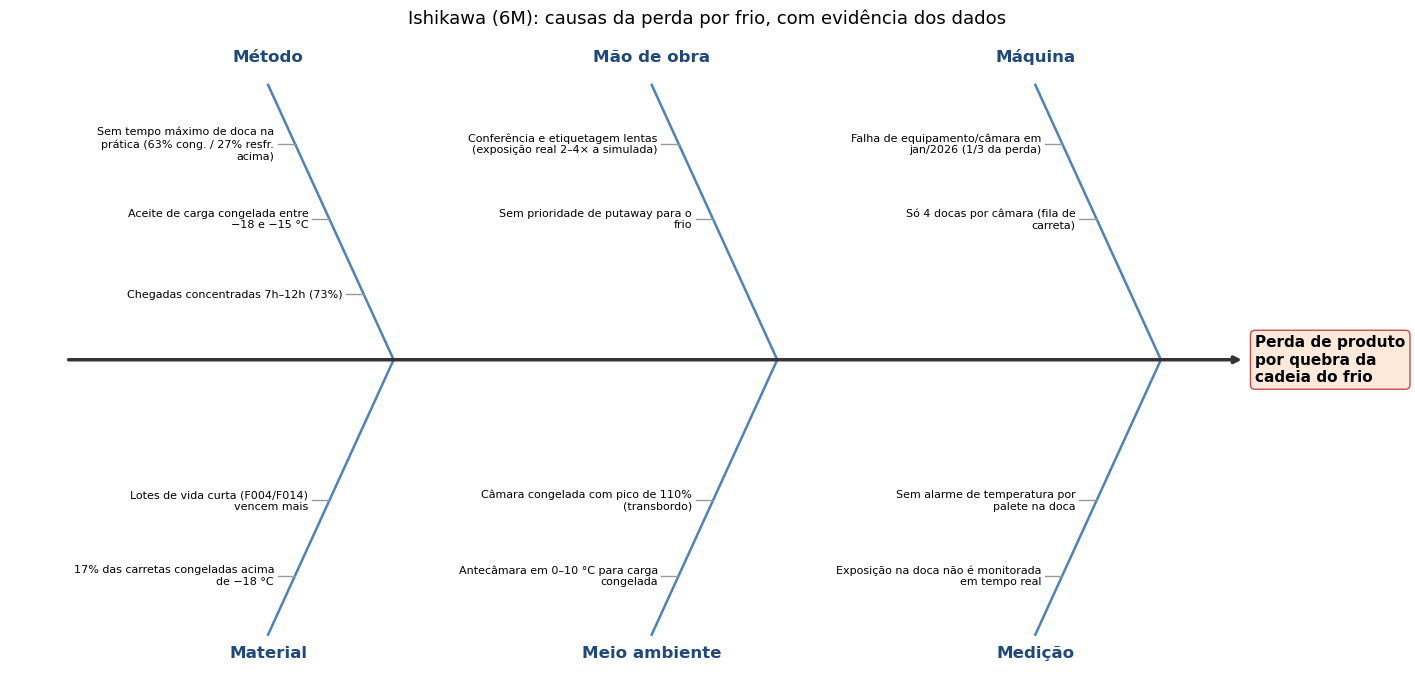

In [5]:
# Diagrama de Ishikawa: organiza as causas em 6 famílias (6M), cada uma com a evidência medida.
ramos = {
    "Método": [f"Sem tempo máximo de doca na prática ({ev['exp_cong']:.0f}% cong. / {ev['exp_res']:.0f}% resfr. acima)",
               "Aceite de carga congelada entre −18 e −15 °C", f"Chegadas concentradas 7h–12h ({ev['pico_manha']:.0f}%)"],
    "Mão de obra": ["Conferência e etiquetagem lentas (exposição real 2–4× a simulada)",
                    "Sem prioridade de putaway para o frio"],
    "Máquina": ["Falha de equipamento/câmara em jan/2026 (1/3 da perda)", "Só 4 docas por câmara (fila de carreta)"],
    "Material": [f"{ev['temp_cong']:.0f}% das carretas congeladas acima de −18 °C",
                 "Lotes de vida curta (F004/F014) vencem mais"],
    "Meio ambiente": ["Antecâmara em 0–10 °C para carga congelada", f"Câmara congelada com pico de {ev['occ_pico']:.0f}% (transbordo)"],
    "Medição": ["Exposição na doca não é monitorada em tempo real", "Sem alarme de temperatura por palete na doca"],
}
import textwrap
fig, ax = plt.subplots(figsize=(18, 8.5)); ax.axis("off")
ax.annotate("", xy=(17.2, 5), xytext=(0.3, 5), arrowprops=dict(arrowstyle="-|>", lw=2.5, color="#333333"))
ax.text(17.35, 5, "Perda de produto\npor quebra da\ncadeia do frio", va="center", fontsize=11, fontweight="bold",
        bbox=dict(boxstyle="round", fc="#FDE9D9", ec="#C0504D"))
posicoes = [(3.2, 1), (8.7, 1), (14.2, 1), (3.2, -1), (8.7, -1), (14.2, -1)]
for (nome, causas), (x, lado) in zip(ramos.items(), posicoes):
    y_fim = 5 + lado * 4.2
    ax.plot([x, x + 1.8], [y_fim, 5], color="#4F81BD", lw=1.8)
    ax.text(x, y_fim + lado * 0.35, nome, ha="center", fontsize=12, fontweight="bold", color="#1F497D")
    for i, c in enumerate(causas):
        y = y_fim - lado * (0.9 + i * 1.15)
        x_r = x + 1.8 * (y - y_fim) / (5 - y_fim)
        ax.plot([x_r - 0.25, x_r], [y, y], color="#999999", lw=1)
        ax.text(x_r - 0.3, y, textwrap.fill(c, 34), ha="right", va="center", fontsize=8)
ax.set_xlim(-0.5, 19.5); ax.set_ylim(0, 10)
ax.set_title("Ishikawa (6M): causas da perda por frio, com evidência dos dados", fontsize=13)
savefig(fig, "09a_ishikawa_frio", out=PH9)

## 3. FMEA do recebimento refrigerado
**RPN = Severidade × Ocorrência × Detecção** (1 a 10 cada; quanto maior o RPN, maior o risco).
- **Severidade:** impacto no produto, no cliente e na segurança do alimento.
- **Ocorrência:** convertida da **taxa medida nos dados** pela escala ao lado (não é chute).
- **Detecção:** quão provável é o controle atual pegar a falha **antes** do dano (10 = não detecta).

| Taxa medida | ≥ 30% | 10–30% | 3–10% | 1–3% | 0,3–1% | < 0,3% |
|---|---|---|---|---|---|---|
| Ocorrência | 9 | 8 | 7 | 5 | 4 | 2 |

In [6]:
def nota_ocorrencia(taxa):
    for lim, n in [(0.30, 9), (0.10, 8), (0.03, 7), (0.01, 5), (0.003, 4)]:
        if taxa >= lim:
            return n
    return 2

erros_put = q("""SELECT AVG(a.lpn IS NOT NULL) AS t FROM fact_receipt r
                 LEFT JOIN (SELECT DISTINCT lpn FROM fact_movement WHERE movement_type = 'ADJUST_RELOCATE') a ON a.lpn = r.lpn
                 WHERE r.status = 'ACCEPTED' AND r.zone <> 'dry'""").t[0]
abaixo70 = (ac.remaining_life_pct < 70).mean()
dias_evento = 13 / 365                               # 06–18/jan/2026
# fração dos dias em que alguma câmara fria teve palete no chão (transbordo)
dias_transbordo = q("""SELECT AVG(t) AS f FROM (SELECT date_key, MAX(overflow_pallets > 0) AS t
                       FROM fact_occupancy_daily WHERE zone <> 'dry' GROUP BY date_key)""").f[0]
fmea = pd.DataFrame([
    # (etapa, modo de falha, efeito, causa, S, taxa, D, controle atual, ação, S', O', D')
    ("Chegada da carreta", "Carga congelada acima de −18 °C aceita", "Produto já degradado entra no estoque",
     "Tolerância até −15 °C; sem registro do termógrafo", 8, ev["temp_cong"] / 100, 6,
     "Leitura pontual do termômetro", "Aceite só com registro do termógrafo da viagem; >−18 °C vai para quarentena e análise", 8, 5, 3),
    ("Descarga", "Palete passa do tempo máximo de doca", "Descongelamento parcial, perda e risco sanitário",
     "Conferência lenta; fila de putaway; sem cronômetro", 9, (ev["exp_cong"] + ev["exp_res"]) / 200, 8,
     "Nenhum controle de tempo", "Cronômetro + alarme por palete; putaway prioritário para frio; conferência na câmara", 9, 4, 3),
    ("Conferência", "Lote com vida útil < 70% aceito", "Vencimento no estoque (72% das unidades vencidas)",
     "Regra não aplicada para alguns fornecedores", 6, abaixo70, 7,
     "Checagem visual da validade", "Bloqueio sistêmico no WMS; scorecard F004/F014", 6, 2, 2),
    ("Putaway", "Palete guardado no endereço errado", "Palete 'some', FEFO e inventário errados",
     "Turno 2 e operador 3; sem leitura obrigatória do endereço", 5, erros_put, 6,
     "Contagem cíclica (detecção tardia)", "Leitura obrigatória do endereço (POP-02); reciclagem", 5, 2, 3),
    ("Armazenagem", "Falha de equipamento da câmara", "Perda em massa (jan/2026: 1/3 da perda do ano)",
     "Manutenção corretiva; sem alarme remoto", 10, dias_evento, 7,
     "Ronda do operador", "Manutenção preventiva + telemetria de temperatura com alarme 24h", 10, 2, 2),
    ("Armazenagem", "Câmara acima de 100% (palete no chão)", "Fluxo de ar bloqueado, avaria, FEFO prejudicado",
     "Pico sazonal; estoque de segurança mal dimensionado", 6, dias_transbordo, 5,
     "Relatório de ocupação", "ES/PP por SKU (Fase 4), slotting (Fase 5), decisão S01 (Fase 8)", 6, 5, 3),
], columns=["etapa", "modo_de_falha", "efeito", "causa", "S", "taxa_medida", "D", "controle_atual", "acao",
            "S_depois", "O_depois", "D_depois"])
fmea["O"] = fmea.taxa_medida.map(nota_ocorrencia)
fmea["RPN"] = fmea.S * fmea.O * fmea.D
fmea["RPN_depois"] = fmea.S_depois * fmea.O_depois * fmea.D_depois
fmea = fmea.sort_values("RPN", ascending=False)
save(fmea, "09a_fmea_recebimento_frio", out=PH9)
fmea[["etapa", "modo_de_falha", "S", "taxa_medida", "O", "D", "RPN", "acao", "RPN_depois"]].round(3)

,etapa,modo_de_falha,S,taxa_medida,O,D,RPN,acao,RPN_depois
1,Descarga,Palete passa do tempo máximo de doca,9,0.449,9,8,648,Cronômetro + alarme por palete; putaway priori...,108
4,Armazenagem,Falha de equipamento da câmara,10,0.036,7,7,490,Manutenção preventiva + telemetria de temperat...,40
0,Chegada da carreta,Carga congelada acima de −18 °C aceita,8,0.173,8,6,384,Aceite só com registro do termógrafo da viagem...,120
5,Armazenagem,Câmara acima de 100% (palete no chão),6,0.311,9,5,270,"ES/PP por SKU (Fase 4), slotting (Fase 5), dec...",90
2,Conferência,Lote com vida útil < 70% aceito,6,0.019,5,7,210,Bloqueio sistêmico no WMS; scorecard F004/F014,24
3,Putaway,Palete guardado no endereço errado,5,0.007,4,6,120,Leitura obrigatória do endereço (POP-02); reci...,30


**Leitura:**
- **Maior RPN:** palete passando do tempo de doca (ocorre em quase metade dos paletes frios e ninguém
  mede) e carga congelada aceita acima de −18 °C. São falhas de **método e medição**, baratas de
  corrigir: POP + cronômetro/alarme + aceite pelo termógrafo. Isso sustenta o VPL do kit de doca fria (Fase 8).
- A falha de equipamento tem severidade máxima e ocorrência baixa: o controle certo é **detecção**
  (telemetria com alarme 24h) e preventiva.
- As ações levam todos os RPN para baixo de ~150. Os POPs da Fase 9 estão em `docs/sops/`.

In [7]:
log(NB, "Pareto de perdas (baixas + devoluções descartadas) por causa; Ishikawa 6M com evidências; FMEA do "
        "recebimento frio com ocorrência convertida da taxa medida")